**Table of contents**<a id='toc0_'></a>    
- [文件说明（File descriptions）](#toc1_)    
- [数据字段（Data fields）](#toc2_)    
- [导入库](#toc3_)    
- [EDA(数据探索性分析)](#toc4_)    
- [工具函数](#toc5_)    
- [数据预处理](#toc6_)    
- [特征工程](#toc7_)    
- [贝叶斯优化参数空间](#toc8_)    
- [合成数据生成（KNN插值版）](#toc9_)    
- [5 折交叉验证训练](#toc10_)    
- [模型融合](#toc11_)    
  - [加权融合（权重按 OOF F1 的幂次）](#toc11_1_)    
  - [Stacking（Logistic/RandomForest 选最佳）](#toc11_2_)    
- [提交文件](#toc12_)    
- [结果可视化](#toc13_)    

<!-- vscode-jupyter-toc-config
    numbering=false
    anchor=true
    flat=false
    minLevel=1
    maxLevel=6
    /vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

# <a id='toc1_'></a> 文件说明（File descriptions）

* PQC_OAV_Dataset_2025.csv - 由加拿大网络安全研究所（CIC）发布的2025年抗量子密码（PQC）网络流量数据集。

# <a id='toc2_'></a> 数据字段（Data fields）


### 流量与体积特征 (Traffic Volume & Flow Features)
- ID - 网络流的唯一标识符
- e2c_total_bytes - 客户端发送或连接交互的总字节数
- e6b_flow_duration_ms - 网络流的持续时间（单位：毫秒）
- e2_client_size - 客户端数据包大小相关特征
- e2_client_record_len - 客户端发送的 TLS 记录（Record）长度
- e2_server_record_len - 服务端发送的 TLS 记录（Record）长度

### 信息熵与时间特征 (Entropy & Temporal Features)


- e4_entropy_h - 数据包头或特定负载的香农信息熵（用于评估加密随机性，高熵通常代表高度加密的数据）
- e5_entropy_c - 客户端负载信息熵
- e6_time_char - 数据包到达的时间间隔/时间分布特征

### 密钥交换与加密算法套件 (Key Exchange & Algorithm Suites)
- e1_alg_suite_mlkem1024 - 标识是否协商使用了 ML-KEM-1024 后量子密钥封装机制（即 Kyber1024，极高安全性）
- e1_alg_suite_mlkem768 - 标识是否协商使用了 ML-KEM-768 后量子加密算法
- e1_alg_suite_x25519 - 标识是否使用了传统的 X25519 椭圆曲线密钥交换算法
- e1_alg_suite_Unknown(0x11eb) - 未知或实验性算法套件的十六进制标识（常见于早期 PQC 草案）
- e1_alg_suite_Unknown(0x11ec) - 另一种未知的算法套件标识
- e1_alg_suite_nan - 缺失或未能解析的算法套件记录
- e3_sig_alg_Unknown(0x0028) - 未知的数字签名算法标识
- e3_sig_alg_nan - 签名算法特征缺失值

### TLS 协议与连接上下文 (TLS Protocol & Connection Context)
- e8_proto_context_TLSv1.2_or_older - TLS 协议版本是否为 1.2 及以下版本（传统连接）
- e8_proto_context_TLSv1.3 - TLS 协议版本是否为 1.3（目前 PQC 混合密钥交换的主要载体）
- e9_conn_outcome_Success - TLS 握手与连接最终结果为成功
- e9_conn_outcome_Failure - TLS 连接失败（可能由于加密套件不匹配或证书错误）
- e9_conn_outcome_Incomplete - TLS 连接未完成（握手被中断）
- e3_cert_parsed - TLS 证书是否被成功解析和验证

### 细粒度 TLS 握手属性 (Fine-grained TLS Attributes)
- e1b_tls_version_SSL3.0 - 客户端/服务端记录中是否包含 SSL 3.0 的兼容性标识
- e1b_tls_version_TLS1.0 - 客户端/服务端记录中是否包含 TLS 1.0 的标识
- e2b_tls_version_SSL3.0 - 另一个视角的 SSL 3.0 版本标识
- e2b_tls_version_TLS1.0 - 另一个视角的 TLS 1.0 版本标识
- e1b_ciphersuite_2 - 提取的特定密码套件 ID 号（通常对应特定的加密协议组合）
- e1b_ciphersuite_54 - 提取的特定密码套件 ID 号
- e1b_ciphersuite_60 - 提取的特定密码套件 ID 号
- e2b_ciphersuite_2 - 响应端的特定密码套件 ID 号
- e2b_ciphersuite_54 - 响应端的特定密码套件 ID 号
- e2b_ciphersuite_60 - 响应端的特定密码套件 ID 号

### 预测目标与数据划分 (Targets & Metadata)
- split - 数据集划分标记（如 train/val/test，用于标准化机器学习模型评估）
- taxonomy - 流量类型的细粒度分类法层级（表示流量所属的子类别或应用类型）
- label - 流量或网络行为的最终判定标签（如 PQC流量、传统流量、良性流量或恶意流量） <font color="red">(Primary Target / 主要预测目标 - 分类任务)</font>

# <a id='toc3_'></a>[导入库](#toc0_)

In [1]:
# ==========================================
# 恶意流量预测（LightGBM + XGBoost + CatBoost）
# 1. 自动贝叶斯优化（LGB/XGB/CAT）
# 2. 数据合成
# 3. 五折 StratifiedKFold 训练
# 4. 加权融合 + Stacking
# 5. SHAP 解释性 + ROC/PR 可视化
# ==========================================
import warnings, os, random, gc, re
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# 设置全局字体，支持中文显示
# ----------------------------
# 解决中文字体 & finXont 报错
# ----------------------------
import matplotlib as mpl

# 让 matplotlib 走 “sans-serif 字体族”
mpl.rcParams["font.family"] = "sans-serif"

# 让中文字体排在最前（有哪个用哪个）
mpl.rcParams["font.sans-serif"] = [
    "Noto Sans CJK SC",      # 你装了 fonts-noto-cjk 后通常就有
    "WenQuanYi Zen Hei",     # fonts-wqy-zenhei
    "WenQuanYi Micro Hei",   # fonts-wqy-microhei
    "SimHei",                # 万一你后来自己装了 SimHei
    "Microsoft YaHei",
    "Arial Unicode MS",
    "DejaVu Sans",           # 最后兜底（不保证中文）
]

# 负号正常显示
mpl.rcParams["axes.unicode_minus"] = False


from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, roc_curve,
    RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

import lightgbm as lgb
import xgboost as xgb
import catboost as cb
import shap
shap.initjs()

In [2]:
TRAIN_PATH = "ml_features_and_labels.csv"
LABEL = 'label'  # 标签名
LABEL_DESC = 'Anomaly Detection'  # 标签描述（在可视化中描述比较抽象的标签名，比如 Target 等）

In [3]:
# ------------------------------------------------------------------
# Paper figures export (WHITELIST)
# 仅将白名单中的论文图表额外保存到 paper_figs/，其余一律不保存到该目录
# ------------------------------------------------------------------
import os
import pandas as pd
import matplotlib.pyplot as plt
from pprint import pprint
PAPER_FIG_DIR = "paper_figs"  # 论文图表保存目录
EXP_FIG_DIR = "exp_figs"  # 普通实验图表保存目录
os.makedirs(PAPER_FIG_DIR, exist_ok=True)
os.makedirs(EXP_FIG_DIR, exist_ok=True)

# 白名单：仅保留论文中除 Fig.1 之外提到的图表/表格
PAPER_WHITELIST = {
    # Figures (paper)
    "fig2_corr_heatmap.png",
    "fig3_shap_bar.png",
    "fig4_shap_summary.png",
    "fig5_shap_dependence.png",
    "shap_dependence_interest_rate.png",
    "shap_dependence_annual_income.png",
    "roc_pr_all_models.png",
    # Tables (paper)
    "table2_model_metrics.csv",
}

def save_paper_figure(filename: str, dpi: int = 300, bbox_inches: str = "tight"):
    """Save current matplotlib figure to paper_figs/ ONLY if filename is in PAPER_WHITELIST."""
    if filename in PAPER_WHITELIST:
        plt.savefig(os.path.join(PAPER_FIG_DIR, filename), dpi=dpi, bbox_inches=bbox_inches)

def save_paper_csv(X: pd.DataFrame, filename: str, **to_csv_kwargs):
    """Save dataframe to paper_figs/ ONLY if filename is in PAPER_WHITELIST."""
    if filename in PAPER_WHITELIST:
        X.to_csv(os.path.join(PAPER_FIG_DIR, filename), **to_csv_kwargs)

def save_exp_figure(filename: str, dpi: int = 300, bbox_inches: str = "tight"):
    """Save current matplotlib figure to exp_figs."""
    plt.savefig(os.path.join(EXP_FIG_DIR, filename), dpi=dpi, bbox_inches=bbox_inches)

def save_exp_csv(X: pd.DataFrame, filename: str, **to_csv_kwargs):
    """Save dataframe to exp_figs."""
    path = os.path.join(EXP_FIG_DIR, filename)
    X.to_csv(path, **to_csv_kwargs)
    print(f'>>> 已保存: {path}')

print(">>> paper_figs 白名单已启用：")
pprint(sorted(PAPER_WHITELIST))

>>> paper_figs 白名单已启用：
['fig2_corr_heatmap.png',
 'fig3_shap_bar.png',
 'fig4_shap_summary.png',
 'fig5_shap_dependence.png',
 'roc_pr_all_models.png',
 'shap_dependence_annual_income.png',
 'shap_dependence_interest_rate.png',
 'table2_model_metrics.csv']


# <a id='toc4_'></a>[EDA(数据探索性分析)](#toc0_)

1. 查看表格数据全貌​
2. 分析数据特征类型与缺失值情况​
3. 探究类别特征与目标特征的关联关系​
4. 剖析数值特征的数据分布特征

In [4]:
train = pd.read_csv(TRAIN_PATH)
train.head()

,e2c_total_bytes,e4_entropy_h,e5_entropy_c,e6_time_char,e6b_flow_duration_ms,e2_client_size,e2_client_record_len,e2_server_record_len,e3_cert_parsed,e1_alg_suite_Unknown(0x11eb),...,e1b_ciphersuite_60,e2b_tls_version_SSL3.0,e2b_tls_version_TLS1.0,e2b_ciphersuite_2,e2b_ciphersuite_54,e2b_ciphersuite_60,label,split,taxonomy,ID
0,8182,4.7889,5.8077,2.45,149.827957,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,train,eval_test_network,net_high_jitter_classic_run1
1,8126,5.0000,5.8367,2.44,231.020927,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,val,eval_test_network,net_high_jitter_classic_run10
2,8272,4.7889,5.9056,2.73,292.967796,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,train,eval_test_network,net_high_jitter_classic_run100
3,8272,4.8125,5.9056,2.31,156.050205,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,test,eval_test_network,net_high_jitter_classic_run101
4,8272,4.8125,5.8367,4.45,193.972111,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,test,eval_test_network,net_high_jitter_classic_run102


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40010 entries, 0 to 40009
Data columns (total 36 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   e2c_total_bytes                    40010 non-null  int64  
 1   e4_entropy_h                       40010 non-null  float64
 2   e5_entropy_c                       37500 non-null  float64
 3   e6_time_char                       39010 non-null  float64
 4   e6b_flow_duration_ms               40010 non-null  float64
 5   e2_client_size                     39510 non-null  float64
 6   e2_client_record_len               40010 non-null  int64  
 7   e2_server_record_len               39010 non-null  float64
 8   e3_cert_parsed                     40010 non-null  bool   
 9   e1_alg_suite_Unknown(0x11eb)       40010 non-null  bool   
 10  e1_alg_suite_Unknown(0x11ec)       40010 non-null  bool   
 11  e1_alg_suite_mlkem1024             40010 non-null  boo

In [6]:
print(train.isnull().sum()) #checking for total null values

e2c_total_bytes                         0
e4_entropy_h                            0
e5_entropy_c                         2510
e6_time_char                         1000
e6b_flow_duration_ms                    0
e2_client_size                        500
e2_client_record_len                    0
e2_server_record_len                 1000
e3_cert_parsed                          0
e1_alg_suite_Unknown(0x11eb)            0
e1_alg_suite_Unknown(0x11ec)            0
e1_alg_suite_mlkem1024                  0
e1_alg_suite_mlkem768                   0
e1_alg_suite_x25519                     0
e1_alg_suite_nan                        0
e8_proto_context_TLSv1.2_or_older       0
e8_proto_context_TLSv1.3                0
e9_conn_outcome_Failure                 0
e9_conn_outcome_Incomplete              0
e9_conn_outcome_Success                 0
e3_sig_alg_Unknown(0x0028)              0
e3_sig_alg_nan                          0
e1b_tls_version_SSL3.0                  0
e1b_tls_version_TLS1.0            

In [7]:
label_map_int2str = {0 : 'No', 1 : 'Yes'}
train[LABEL_DESC] = train[LABEL].map(label_map_int2str)

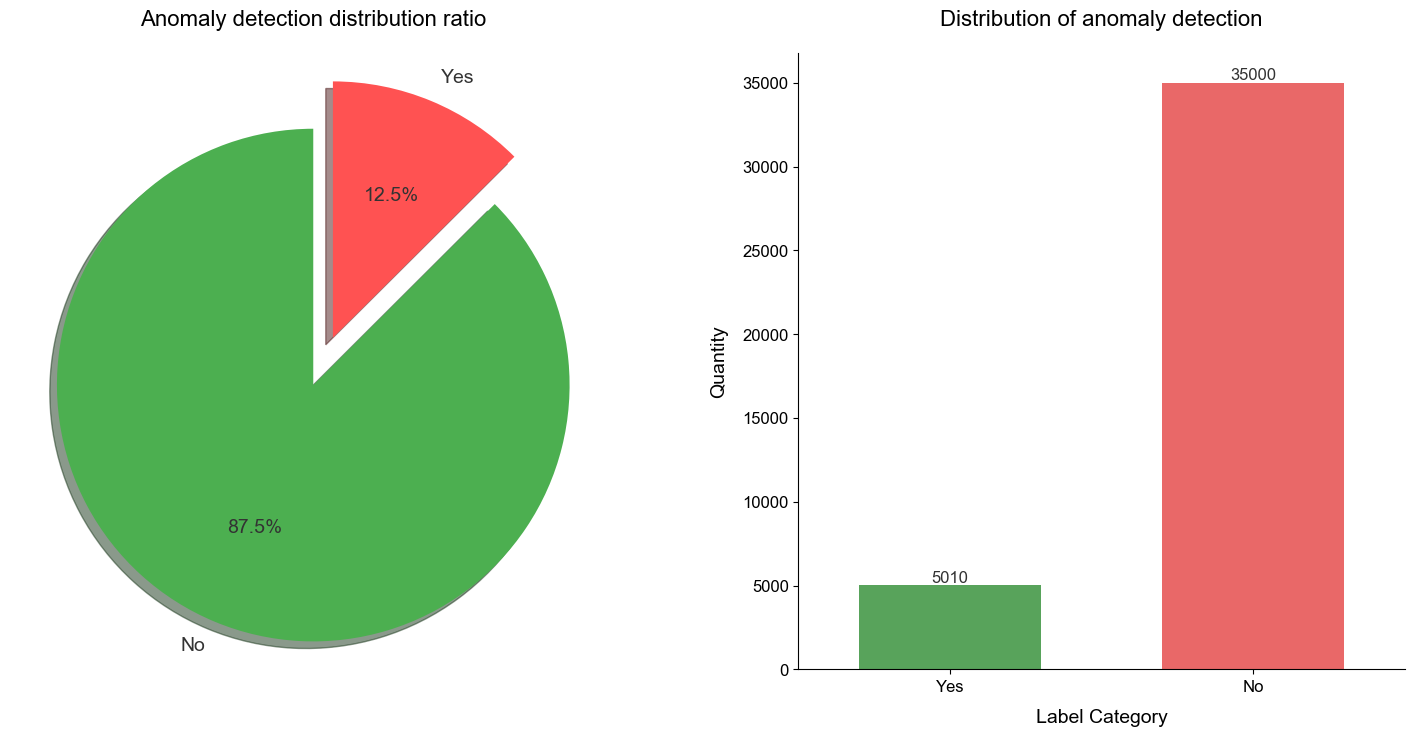

In [8]:
from utils import plot_classify_label_distribution

plot_classify_label_distribution(
    df=train, label_desc=LABEL_DESC,
    # pie_title=f'{LABEL_DESC} distribution ratio'.capitalize(),
    # bar_title=f'distribution of {LABEL_DESC}'.capitalize(),
)

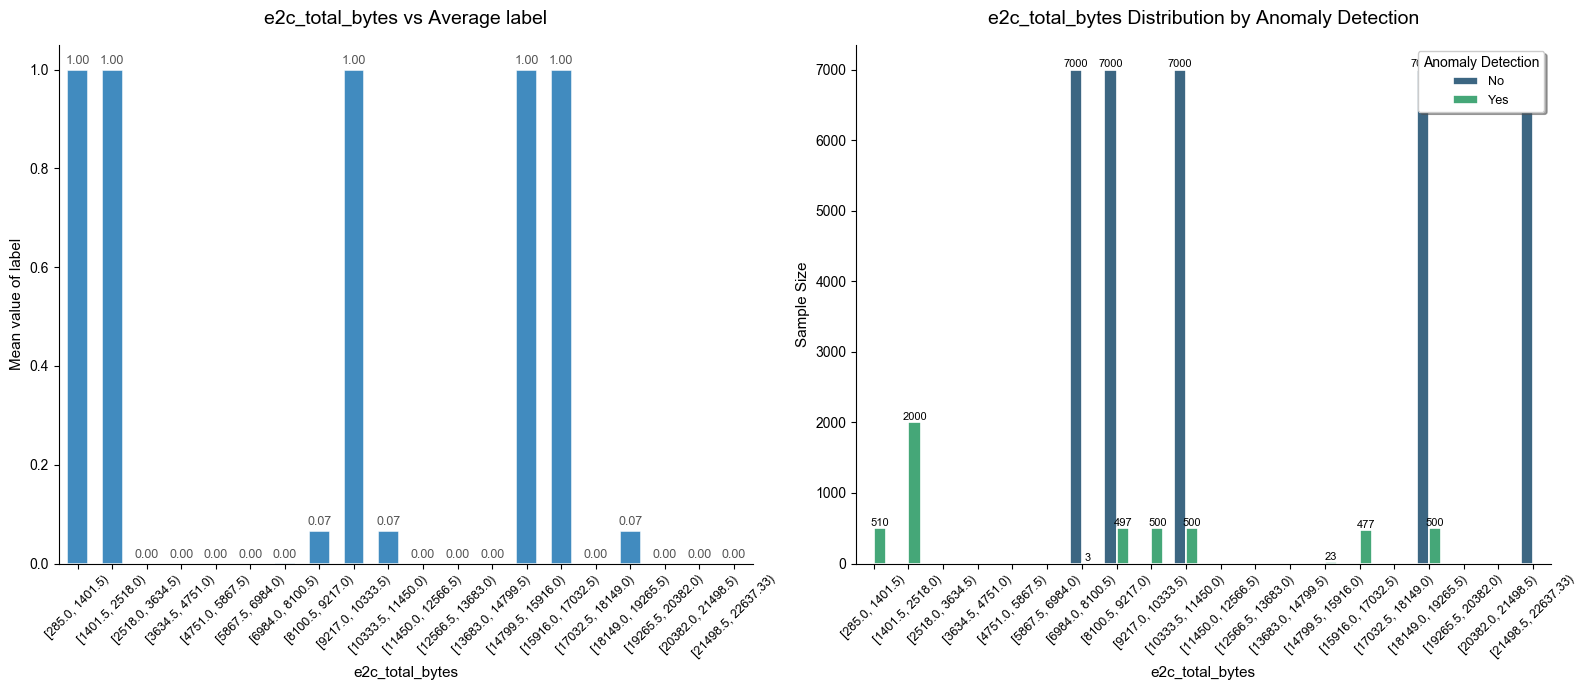

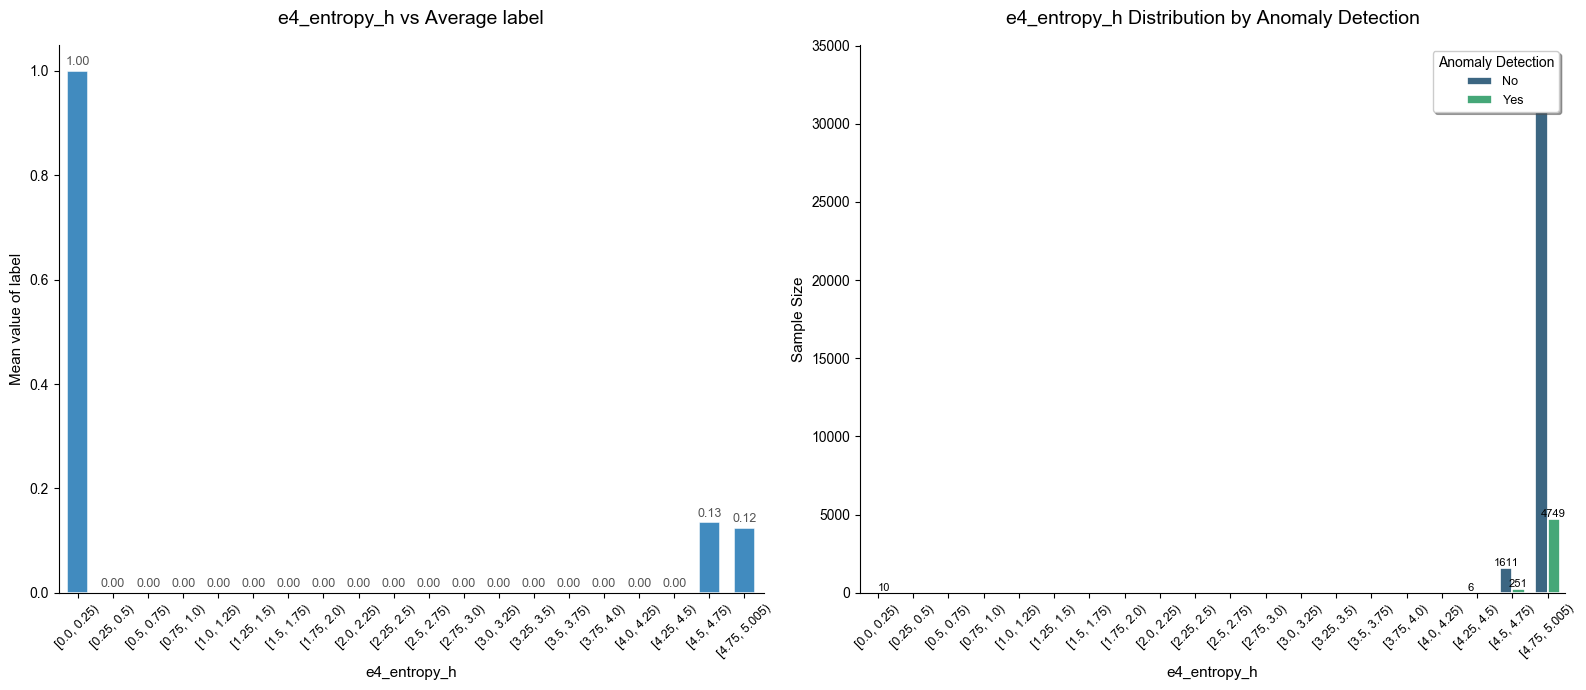

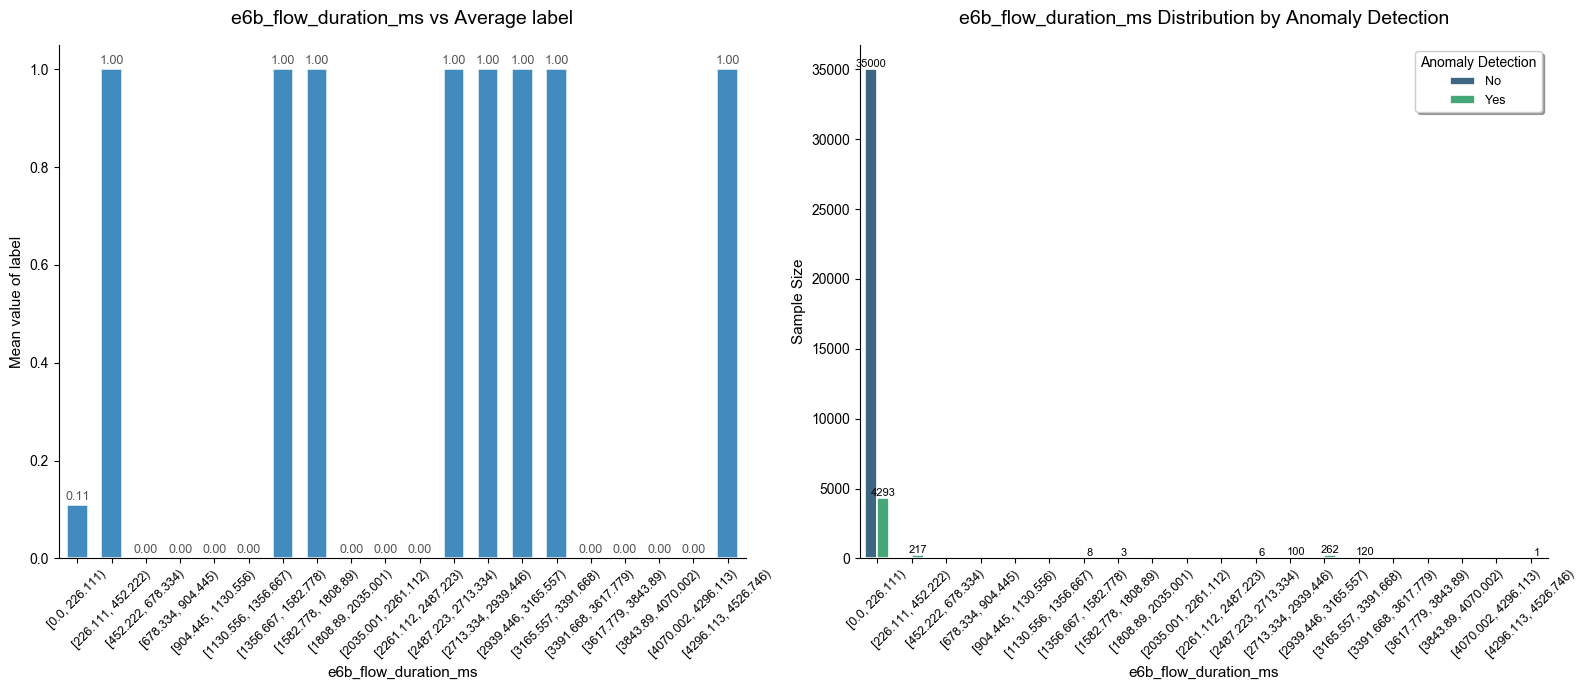

In [9]:
from utils import plot_continuous_variable_label_relationship

continuous_variables = [
    # 'Film_Thickness_nm', 'Annealing_Temp_C', 'Nanostructure_Size_nm',
    # 'Gate_Length_um', 'Gate_Width_um', 'Mobility_cm2V-1s-1',
    # 'Threshold_Voltage_V', 'On_Off_Ratio', 'Subthreshold_Swing_Vdec',
    # 'Gate_Density_gates_per_mm2', 'Bending_Radius_mm', 'Cycles_to_Failure',
    # 'Power_Consumption_mW', 'SNN_Accuracy_%', 'Response_Time_ms',
    'e2c_total_bytes', 'e4_entropy_h', 'e6b_flow_duration_ms'
]
for var in continuous_variables:
    plot_continuous_variable_label_relationship(
        df=train,
        var=var,
        label=LABEL,
        label_desc=LABEL_DESC,
        bins=20,
        names=None,
    )

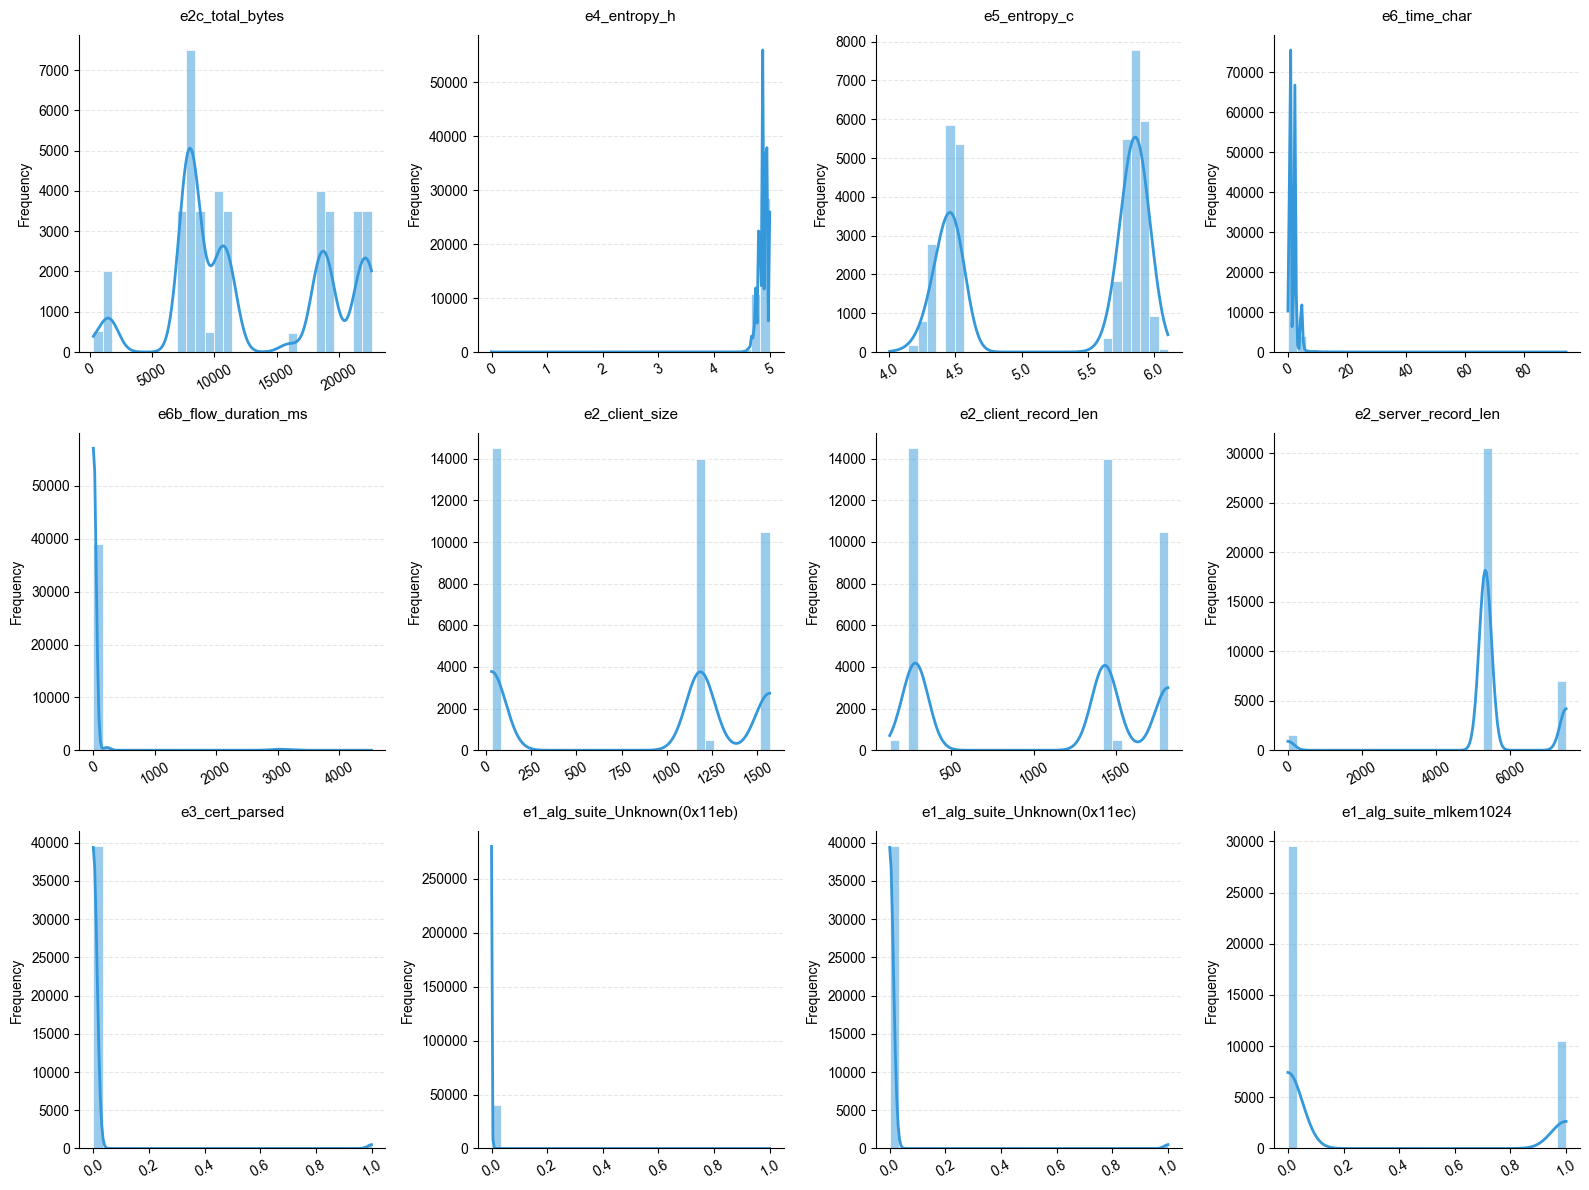

In [10]:
from utils import plot_variables_distribution

# 主要特征
NUM_FEATURE_NAMES = ['e2c_total_bytes', 'e4_entropy_h', 'e5_entropy_c', 'e6_time_char',
       'e6b_flow_duration_ms', 'e2_client_size', 'e2_client_record_len',
       'e2_server_record_len', 'e3_cert_parsed',
       'e1_alg_suite_Unknown(0x11eb)', 'e1_alg_suite_Unknown(0x11ec)',
       'e1_alg_suite_mlkem1024', 'e1_alg_suite_mlkem768',
       'e1_alg_suite_x25519', 'e1_alg_suite_nan']
plot_variables_distribution(
    df=train,
    variables=NUM_FEATURE_NAMES,
)

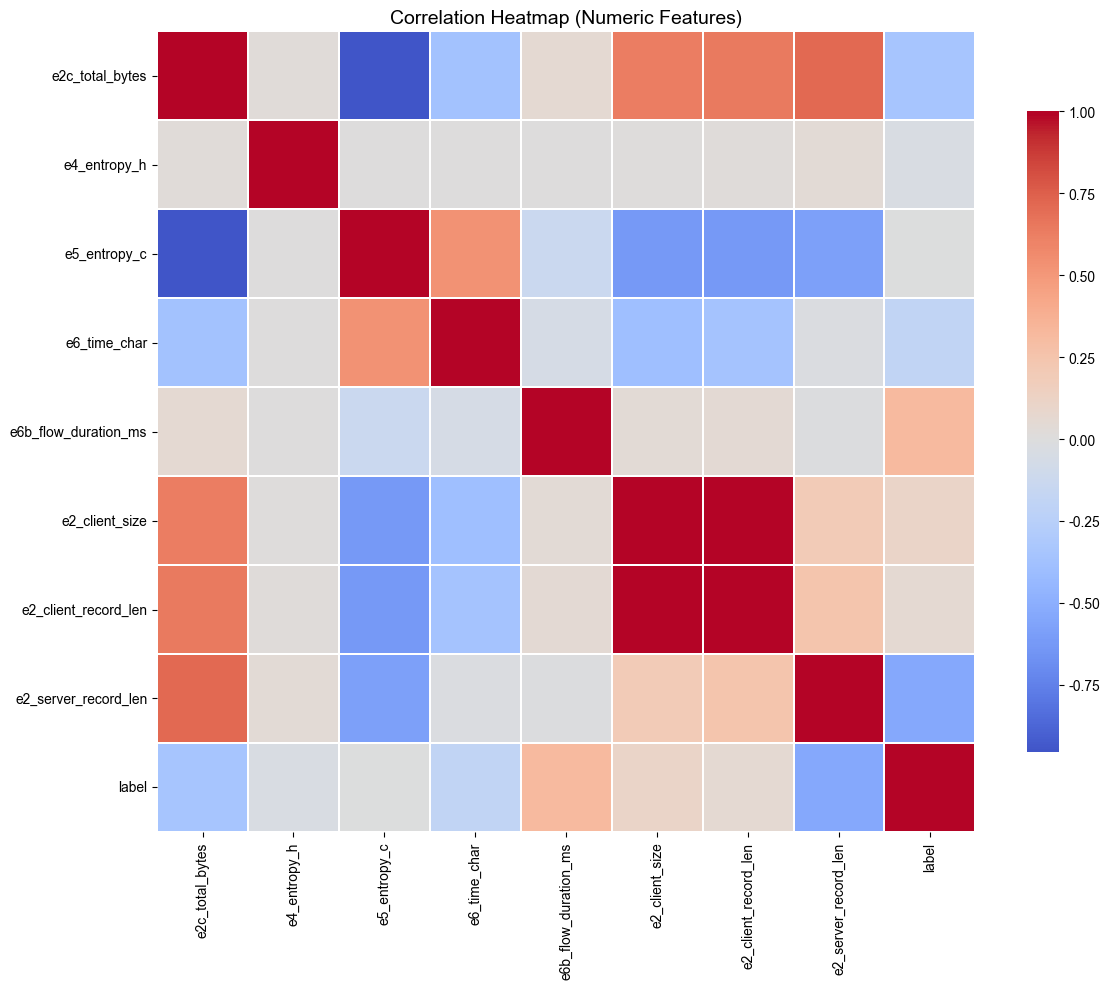

In [11]:
# ------------------------------------------------------------------
# Figure (Paper-like): Correlation Heatmap (Numeric Features)
# ------------------------------------------------------------------
from utils import plot_heatmap

plot_heatmap(train)
save_paper_figure('fig2_corr_heatmap.png', dpi=300, bbox_inches='tight')


# <a id='toc6_'></a>[数据预处理](#toc0_)


功能：处理数据中不规范列名与字符串，处理数据中的缺失值和异常值，同时记录异常/缺失标记，为建模做准备

In [12]:
class DataPreprocessing:
    def __init__(self):
        # 存储数值型特征的中位数（用于填充缺失值）
        self.medians = None
        # 存储特征的众数（主要用于类别型特征的缺失值填充）
        self.modes = None

    def fit(self, X):
        """从训练数据中学习统计特征（中位数、众数）"""
        # 复制输入数据，避免修改原始数据
        X = X.copy()
        # 计算所有数值型特征的中位数（忽略非数值型特征）
        self.medians = X.median(numeric_only=True)
        # 计算所有特征的众数（取第一个众数，若存在多个众数）
        self.modes = X.mode().iloc[0]

    def transform(self, X):
        """对数据进行清洗转换：处理异常值、填充缺失值、添加标记列"""
        # 复制输入数据，避免修改原始数据
        X = X.copy()
        # 统一用对应特征的中位数填充
        X.fillna(self.medians, inplace=True)

        # 返回处理后的数据集
        return X

# <a id='toc7_'></a>[特征工程](#toc0_)

- 1. PQC 与后量子密码安全特征构建
基于后量子密码（PQC）迁移理论，通过协议套件构成识别加密强度与迁移状态：
- 后量子与混合加密状态：识别 ML-KEM（原 Kyber）等新一代算法的使用情况，并结合传统曲线（如 x25519）判定系统是否处于抗量子攻击的混合加密过渡阶段。

- 协议降级与异常风险指数：通过对旧版协议（如 SSL3.0, TLS1.0）的逻辑组合构建降级攻击风险指标，并捕获未知或非标准密码套件，识别潜在的中间人劫持或协议绕过风险。

- 2. 性能、连通性与 PQC 兼容性评估
针对 PQC 算法带来的大载荷与高计算开销，构建反映中间设备（Middlebox）兼容性的特征：
- 吞吐量与时间开销：计算单位毫秒内的字节传输速率及每字节的时间成本，量化 PQC 算法由于公钥与密文长度增加对网络延迟的实际影响。
- PQC 握手失败敏感度：耦合 PQC 使用标志与连接失败状态，识别由于网络中间设备因不识别 PQC 载荷或包重组限制而导致的连接丢弃（Middlebox Drop）。


- 3. 流量对称性与载荷拓扑特征
利用流量双向交互的结构性特征，识别不同加密算法下的行为模式：
- 客户端上行占比与非对称指数：计算客户端数据分布及记录长度的非对称性，区分典型的请求-响应模式与异常的数据外泄或隧道流量。
- PQC 证书开销估算：通过证书解析状态与服务器记录长度的乘积，量化 PQC 证书（如基于 Dilithium）带来的额外握手数据量。

- 4. 熵值分析与隐蔽混淆检测
基于信息论原理，通过信息熵的分布判定载荷是否经过高强度混淆或存在隐蔽通道：
- 熵值差异度：计算头部熵与内容熵的绝对差（Entropy Delta），用于区分具有结构化特征的加密流量与无明显特征的混淆流量。
- 高熵低效连接识别：提取具有极高内容熵（>7.5）且总字节数较小的连接特征，用以精准识别加密的心跳包、命令控制（C2）信道或高度混淆的短连接。

In [ ]:
class FeatureGenerator:
    """特征生成器类，用于对输入数据进行特征工程处理，生成模型所需的特征"""
    
    def transform(self, X):
        """
        对输入数据进行特征转换处理
        
        参数:
            X: pandas.DataFrame，原始输入数据
            
        返回:
            pandas.DataFrame，处理后的特征数据
        """
        # 复制输入数据，避免修改原始数据
        df_features = X.copy()
        # ==========================================
        # 1. PQC 与密码学安全特征 (Cryptographic & PQC Metrics)
        # ==========================================
        
        # 1. 后量子算法使用标志
        # 假设列的值为 0 或 1，使用 | 进行按位或运算
        df_features['PQC_Usage_Flag'] = (df_features['e1_alg_suite_mlkem1024'] | 
                                        df_features['e1_alg_suite_mlkem768'])
        
        # 2. 混合加密状态 (Hybrid Crypto)
        df_features['Hybrid_Crypto_Mode'] = (df_features['PQC_Usage_Flag'] & 
                                            df_features['e1_alg_suite_x25519'])
        
        # 3. 协议降级攻击风险指数 (Downgrade Attack Risk)
        df_features['Downgrade_Attack_Risk'] = (df_features['e1b_tls_version_SSL3.0'] | 
                                                df_features['e1b_tls_version_TLS1.0'] | 
                                                df_features['e2b_tls_version_SSL3.0'] | 
                                                df_features['e2b_tls_version_TLS1.0'])
        
        # 4. 异常/未知密码学套件标志
        df_features['Unknown_Cipher_Anomaly'] = (df_features['e1_alg_suite_Unknown(0x11eb)'] | 
                                                df_features['e1_alg_suite_Unknown(0x11ec)'] | 
                                                df_features['e1_alg_suite_nan'] | 
                                                df_features['e3_sig_alg_Unknown(0x0028)'])

        # ==========================================
        # 2. 性能与网络连通性特征 (Performance & Connectivity)
        # ==========================================
        
        # 5. 吞吐量/带宽速率 (Bytes per ms)
        # 加上 1e-6 防止除以 0
        df_features['Throughput_Bytes_per_ms'] = df_features['e2c_total_bytes'] / (df_features['e6b_flow_duration_ms'] + 1e-6)
        
        # 6. PQC 握手失败敏感度 (Middlebox 丢弃特征)
        # 发生 PQC 且 连接结果为失败或不完整
        df_features['PQC_Middlebox_Failure'] = (df_features['PQC_Usage_Flag'] & 
                                                (df_features['e9_conn_outcome_Failure'] | df_features['e9_conn_outcome_Incomplete']))

        #以上为交互构造特征，以下为比例特征

        # 7. 每字节时间开销 (Time Cost Per Byte)
        df_features['Time_Cost_Per_Byte'] = df_features['e6b_flow_duration_ms'] / (df_features['e2c_total_bytes'] + 1)

        # ==========================================
        # 3. 流量对称性与载荷特征 (Traffic Asymmetry & Payload)
        # ==========================================
        
        # 8. 客户端上行数据占比
        df_features['Client_Upload_Ratio'] = df_features['e2_client_size'] / (df_features['e2c_total_bytes'] + 1)
        
        # 9. 记录长度非对称指数 (范围 -1 到 1)
        asymmetry_num = df_features['e2_client_record_len'] - df_features['e2_server_record_len']
        asymmetry_den = df_features['e2_client_record_len'] + df_features['e2_server_record_len'] + 1
        df_features['Record_Length_Asymmetry'] = asymmetry_num / asymmetry_den
        
        # 10. PQC 证书开销估算
        df_features['PQC_Cert_Overhead_Indicator'] = df_features['e3_cert_parsed'] * df_features['e2_server_record_len']

        # ==========================================
        # 4. 熵与混淆检测特征 (Entropy & Obfuscation)
        # ==========================================
        
        # 11. 熵值差异度 (Header熵与Content熵的绝对差)
        df_features['Entropy_Delta'] = np.abs(df_features['e4_entropy_h'] - df_features['e5_entropy_c'])
        
        # 12. 高熵低效连接标志 (布尔值转为整数)
        # 内容熵大于7.5（高度加密/混淆）且总字节数小于1000（极短连接）
        df_features['High_Entropy_Low_Bytes'] = ((df_features['e5_entropy_c'] > 7.5) & 
                                                (df_features['e2c_total_bytes'] < 1000)).astype(int)

        return df_features

1. 从训练数据中分离目标变量（转为整数）和特征数据，复制测试数据。
2. 用训练特征拟合预处理模型，再分别对训练和测试特征做预处理。
3. 通过特征生成器对预处理后的训练、测试特征进行特征工程，确保处理一致性，为建模做准备。

In [14]:
train_data = train[train['split']=='train']
train_X = train_data.drop(columns=[LABEL, LABEL_DESC, 'split','taxonomy','ID'])
train_y = train_data[LABEL]

test = train[train['split']=='test']
test_X = test.drop(columns=[LABEL, LABEL_DESC, 'split','taxonomy','ID'])
test_y = test[LABEL]


# 初始化数据预处理类实例（假设该类包含缺失值处理、异常值处理等基础预处理逻辑）
preprocessor = DataPreprocessing()

# 用训练数据拟合预处理模型（学习训练数据中的统计特性，如缺失值填充策略等）
preprocessor.fit(train_X)

# 对训练特征数据应用预处理（使用拟合好的参数对训练数据进行转换）
train_proc = preprocessor.transform(train_X)

# 对测试特征数据应用同样的预处理（保证训练集和测试集处理方式一致）
test_proc  = preprocessor.transform(test_X)

# 初始化特征生成器实例（即前面定义的FeatureGenerator类，用于生成高级特征）
feat_gen = FeatureGenerator()

# 对预处理后的训练数据进行特征工程（生成衍生特征，如比例特征、交互特征等）
train_fe = feat_gen.transform(train_proc)

# 对预处理后的测试数据进行同样的特征工程（保持特征一致性）
test_fe  = feat_gen.transform(test_proc)

1. 精准划分特征类型
2. 为不同特征类型构建专属处理管道
3. 整合列转换器与应用完整处理流程

In [15]:
def clean_feature_names(columns):
    new_columns = []
    for col in columns:
        # 1. 替换特殊字符 (括号, &, %, 逗号) 为下划线
        new_col = re.sub(r'[(),&%\s:-]+', '_', col)
        # 2. 去除首尾可能的下划线
        new_col = new_col.strip('_')
        new_columns.append(new_col)

    return new_columns

In [16]:
from utils import construct_process_pipeline

# 划分类别型特征列：筛选数据类型为object的列（通常为字符串类型的类别特征）
cat_cols = [c for c in train_fe.columns if train_fe[c].dtype == 'object']

# 划分数值型特征列：除类别特征外的其他列（通常为int/float类型的连续或离散数值特征）
num_cols = [c for c in train_fe.columns if c not in cat_cols]

# 构建预处理流程管道
preprocess = construct_process_pipeline(num_cols, cat_cols)

# 用训练集拟合完整的预处理流程（学习数值特征的中位数、类别特征的众数和编码规则等）
# 并对训练特征数据进行最终转换，得到可直接输入模型的特征矩阵
X_train = preprocess.fit_transform(train_fe)
columns = clean_feature_names(preprocess.get_feature_names_out())  # 处理特征名称中的违规符号
X_train = pd.DataFrame(X_train, columns=columns)

# 用拟合好的预处理流程转换测试特征数据（保证与训练集处理逻辑完全一致）
X_test = preprocess.transform(test_fe)
X_test = pd.DataFrame(X_test, columns=columns)

In [17]:
X_train.head()

,e2c_total_bytes,e4_entropy_h,e5_entropy_c,e6_time_char,e6b_flow_duration_ms,e2_client_size,e2_client_record_len,e2_server_record_len,e3_cert_parsed,e1_alg_suite_Unknown_0x11eb,...,Downgrade_Attack_Risk,Unknown_Cipher_Anomaly,Throughput_Bytes_per_ms,PQC_Middlebox_Failure,Time_Cost_Per_Byte,Client_Upload_Ratio,Record_Length_Asymmetry,PQC_Cert_Overhead_Indicator,Entropy_Delta,High_Entropy_Low_Bytes
0,8182.0,4.7889,5.8077,2.45,149.827957,32.0,285.0,5316.0,0.0,0.0,...,1.0,0.0,54.609301,0.0,0.018310,0.003911,-0.898072,0.0,1.0188,0.0
1,8272.0,4.7889,5.9056,2.73,292.967796,32.0,285.0,5316.0,0.0,0.0,...,1.0,0.0,28.235185,0.0,0.035413,0.003868,-0.898072,0.0,1.1167,0.0
2,8272.0,4.8125,5.8657,2.98,251.286983,32.0,285.0,5316.0,0.0,0.0,...,1.0,0.0,32.918537,0.0,0.030374,0.003868,-0.898072,0.0,1.0532,0.0
3,8272.0,5.0000,5.9056,2.41,138.040066,32.0,285.0,5316.0,0.0,0.0,...,1.0,0.0,59.924631,0.0,0.016686,0.003868,-0.898072,0.0,0.9056,0.0
4,8272.0,4.9375,5.7678,2.33,165.041923,32.0,285.0,5316.0,0.0,0.0,...,1.0,0.0,50.120598,0.0,0.019949,0.003868,-0.898072,0.0,0.8303,0.0


# <a id='toc8_'></a>[贝叶斯优化参数空间](#toc0_)

In [18]:
# ------------------------------------------------------------------
# 小样本快速优化（用 3 折 & 700 样本）
# ------------------------------------------------------------------
train_size = 800 if X_train.shape[0] > 800 else int(X_train.shape[0] * 0.8)
sample_idx, _ = train_test_split(
    np.arange(X_train.shape[0]), stratify=train_y, train_size=train_size, random_state=42
)
X_sample, y_sample = X_train.iloc[sample_idx], train_y.iloc[sample_idx]

class_weight = len(train_y) / (2 * np.bincount(train_y))  # 类别权重
xgb_scale_weight = class_weight[1] / class_weight[0] if 'class_weight' in locals() else 1.0

In [19]:
from utils import (
    bayes_opt,
    lgb_space, xgb_space, cat_space,
)

# ================= 提升树模型 (Boosting) =================
print('【LightGBM 贝叶斯优化】')
model = lgb.LGBMClassifier(class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1)
lgb_model, lgb_best = bayes_opt(model, lgb_space, X_sample, y_sample, cv=3, n_iter=12)

print('【XGBoost 贝叶斯优化】')
model = xgb.XGBClassifier(
    objective='binary:logistic', eval_metric='logloss', tree_method='hist',
    n_jobs=-1, scale_pos_weight=xgb_scale_weight, random_state=42,
)
xgb_model, xgb_best = bayes_opt(model, xgb_space, X_sample, y_sample, cv=3, n_iter=12)

print('【CatBoost 贝叶斯优化】')
model = cb.CatBoostClassifier(
    loss_function='Logloss', eval_metric='F1', thread_count=-1,
    auto_class_weights='Balanced', random_state=42, verbose=False,
)
cat_model, cat_best = bayes_opt(model, cat_space, X_sample, y_sample, cv=3, n_iter=1)

【LightGBM 贝叶斯优化】
【XGBoost 贝叶斯优化】
【CatBoost 贝叶斯优化】


# <a id='toc9_'></a>[合成数据生成（KNN插值版）](#toc0_)
功能：通过KNN插值法为少数类生成合成样本，缓解数据不平衡问题

In [20]:
from utils import apply_sampling

# 设置采样策略，可选值：none / smote / undersample / combined / knn
SAMPLING_STRATEGY = 'smote'
# 打印当前使用的采样策略
print(f'>>> 数据采样策略：{SAMPLING_STRATEGY}')

>>> 数据采样策略：smote


# <a id='toc10_'></a>[5 折交叉验证训练](#toc0_)

In [21]:
from utils import f1_best_threshold, get_best_f1

# 提升树模型 (Boosting)
oof_lgb, pred_lgb = np.zeros(X_train.shape[0]), np.zeros(X_test.shape[0])
oof_xgb, pred_xgb = np.zeros(X_train.shape[0]), np.zeros(X_test.shape[0])
oof_cat, pred_cat = np.zeros(X_train.shape[0]), np.zeros(X_test.shape[0])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for fold, (trn, val) in enumerate(skf.split(X_train, train_y), 1):
    print(f'=== Fold {fold} ===')
    X_resample, X_val = X_train.iloc[trn], X_train.iloc[val]
    y_resample, y_val = train_y.iloc[trn], train_y.iloc[val]

    # 采样仅对训练集
    X_trn, y_trn = apply_sampling(X_resample, y_resample, strategy=SAMPLING_STRATEGY)

    # ------------------------------------------------------
    # Boosting 类模型 (支持 eval_set 早停)
    # ------------------------------------------------------
    #  LightGBM
    m_lgb = lgb.LGBMClassifier(**lgb_best, class_weight='balanced', n_jobs=-1, verbose=-1)
    m_lgb.fit(X_trn, y_trn, eval_set=[(X_val, y_val)]) # callbacks=[lgb.early_stopping(50)] 可选
    oof_lgb[val] = m_lgb.predict_proba(X_val)[:, 1]
    pred_lgb += m_lgb.predict_proba(X_test)[:, 1] / skf.n_splits

    #  XGBoost
    neg, pos = np.bincount(y_trn)
    spw = neg / pos
    m_xgb = xgb.XGBClassifier(
        **xgb_best, tree_method='hist', n_jobs=-1,
        scale_pos_weight=spw, early_stopping_rounds=50
    )
    m_xgb.fit(X_trn, y_trn, eval_set=[(X_val, y_val)], verbose=0)
    oof_xgb[val] = m_xgb.predict_proba(X_val)[:, 1]
    pred_xgb += m_xgb.predict_proba(X_test)[:, 1] / skf.n_splits

    #  CatBoost
    m_cat = cb.CatBoostClassifier(
        **cat_best, thread_count=-1, verbose=False,
        auto_class_weights='Balanced', early_stopping_rounds=50
    )
    m_cat.fit(X_trn, y_trn, eval_set=(X_val, y_val))
    oof_cat[val] = m_cat.predict_proba(X_val)[:, 1]
    pred_cat += m_cat.predict_proba(X_test)[:, 1] / skf.n_splits

    print(f"   [Boosting] LGB:{get_best_f1(y_val, oof_lgb[val]):.3f} | XGB:{get_best_f1(y_val, oof_xgb[val]):.3f} | CAT:{get_best_f1(y_val, oof_cat[val]):.3f}")
    print("-" * 50)

=== Fold 1 ===
   [Boosting] LGB:0.885 | XGB:0.885 | CAT:0.885
--------------------------------------------------
=== Fold 2 ===
   [Boosting] LGB:0.897 | XGB:0.900 | CAT:0.900
--------------------------------------------------
=== Fold 3 ===
   [Boosting] LGB:0.879 | XGB:0.878 | CAT:0.880
--------------------------------------------------
=== Fold 4 ===
   [Boosting] LGB:0.896 | XGB:0.894 | CAT:0.894
--------------------------------------------------
=== Fold 5 ===
   [Boosting] LGB:0.870 | XGB:0.871 | CAT:0.871
--------------------------------------------------


# <a id='toc11_'></a>[最优模型选择（无模型融合）](#toc0_)


## <a id='toc11_1_'></a>[基于 OOF F1 的最优单模型选择](#toc0_)


In [22]:
# ======================================================
# 无模型融合版本：直接选择最优单模型（按 OOF 最佳 F1）
# ======================================================

# 1. 整理所有模型的 OOF 和 Test 预测值
# 格式: (短名, OOF数组, Test概率数组)
model_list = [
    ('LGB',  oof_lgb,  pred_lgb),
    ('XGB',  oof_xgb,  pred_xgb),
    ('CAT',  oof_cat,  pred_cat)
]

# 2. 选择最佳单模型（基于 OOF 的最佳 F1）
name_map = {
    'LGB': 'LightGBM',
    'XGB': 'XGBoost',
    'CAT': 'CatBoost'
}

best_short = None
best_model_name = None
best_model_oof = None
best_model_test = None
best_thr = None
best_f1 = -1

print("=== 单模型 OOF 最佳 F1 表现 ===")
for short, oof, pred in model_list:
    # f1_best_threshold 返回 (threshold, f1_score)
    thr, f1 = f1_best_threshold(train_y, oof)
    print(f"{short:4s} | F1={f1:.4f} @ thr={thr:.4f}")
    if f1 > best_f1:
        best_f1 = f1
        best_thr = thr
        best_short = short
        best_model_name = name_map.get(short, short)
        best_model_oof = oof
        best_model_test = pred

print(f"\n>>> 最佳单模型（无融合）: 【{best_model_name}】({best_short})")
print(f">>> OOF 最佳 F1 : {best_f1:.4f}")
print(f">>> OOF 最佳阈值: {best_thr:.4f}")

# 3. 最终用于提交的 Test 概率（直接使用最佳单模型）
final_prob_test = best_model_test

=== 单模型 OOF 最佳 F1 表现 ===
LGB  | F1=0.8851 @ thr=0.9686
XGB  | F1=0.8851 @ thr=0.6808
CAT  | F1=0.8853 @ thr=0.7155

>>> 最佳单模型（无融合）: 【CatBoost】(CAT)
>>> OOF 最佳 F1 : 0.8853
>>> OOF 最佳阈值: 0.7155


In [23]:
# ------------------------------------------------------------------
# Table (Paper-like): Model Performance Summary (OOF)
# ------------------------------------------------------------------
import os
import pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

# 说明：这里使用 OOF 概率 + best_thr（最佳单模型阈值）做二值化，计算 Accuracy/F1；AUC 直接用概率
rows = []
for name, oof, _ in model_list:
    # 默认用全局 best_thr；如果你更想每个模型都用各自最优阈值，可改为 f1_best_threshold(y, oof)
    y_pred = (oof >= best_thr).astype(int)
    rows.append({
        'Model': name,
        'Accuracy(thr=best_thr)': accuracy_score(train_y, y_pred),
        'F1(thr=best_thr)': f1_score(train_y, y_pred),
        'ROC_AUC': roc_auc_score(train_y, oof),
    })

metrics_df = pd.DataFrame(rows).sort_values('ROC_AUC', ascending=False)
display(metrics_df)
save_exp_csv(metrics_df, 'model_performance_oof.csv', index=False)

,Model,Accuracy(thr=best_thr),F1(thr=best_thr),ROC_AUC
1,XGB,0.974131,0.884936,0.981307
2,CAT,0.974215,0.885307,0.981279
0,LGB,0.972590,0.879663,0.980625


>>> 已保存: exp_figs/model_performance_oof.csv


In [24]:
# ------------------------------------------------------------------
# Export: Model Metrics Table (Paper-like Table II) + Simple Bars
# ------------------------------------------------------------------
import os
import pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

rows = []
# 复用前面 model_list: (name, oof, pred)
for name, oof, _ in model_list:
    # 默认阈值 0.5 的 accuracy/f1（也可以用 best_thr，但为可比性这里统一 0.5）
    y_pred = (oof >= 0.5).astype(int)
    rows.append({
        'Model': name,
        'ROC_AUC': roc_auc_score(train_y, oof),
        'Accuracy@0.5': accuracy_score(train_y, y_pred),
        'F1@0.5': f1_score(train_y, y_pred)
    })

# 加入最佳单模型（无融合）
rows.append({
    'Model': f'Best({best_short})',
    'ROC_AUC': roc_auc_score(train_y, best_model_oof),
    'Accuracy@0.5': accuracy_score(train_y, (best_model_oof >= 0.5).astype(int)),
    'F1@0.5': f1_score(train_y, (best_model_oof >= 0.5).astype(int))
})
df_metrics = pd.DataFrame(rows).sort_values('ROC_AUC', ascending=False)
save_exp_csv(df_metrics, 'table2_model_metrics.csv', index=False)
save_paper_csv(df_metrics, 'table2_model_metrics.csv', index=False)

>>> 已保存: exp_figs/table2_model_metrics.csv


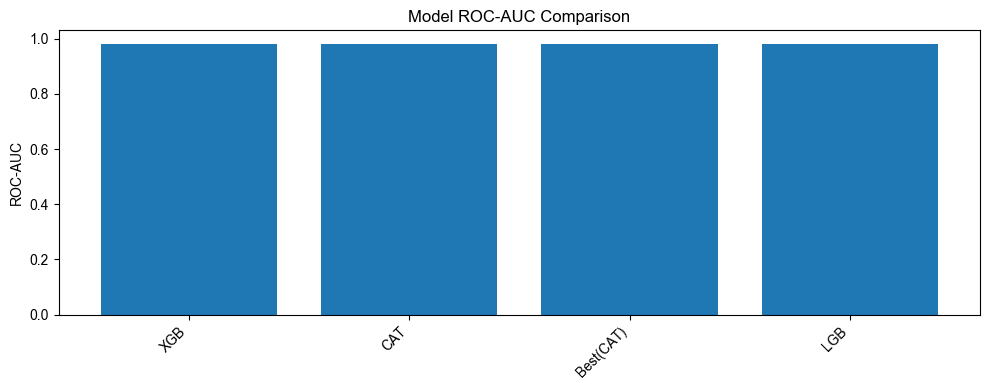

In [25]:
# 简单柱状图：ROC-AUC
plt.figure(figsize=(10, 4))
plt.bar(df_metrics['Model'], df_metrics['ROC_AUC'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('ROC-AUC')
plt.title('Model ROC-AUC Comparison')
plt.tight_layout()
save_exp_figure('model_auc_bar.png')
plt.show()
plt.close()

## <a id='toc11_2_'></a>[（已移除）Stacking/融合](#toc0_)

本版本已去除加权融合与 Stacking，仅保留“最优单模型选择”。


In [26]:
# Stacking / 融合已移除：本版本不再训练元模型。

# <a id='toc12_'></a>[提交文件](#toc0_)



In [27]:
# sub[LABEL] = (final_prob_test >= best_thr).astype(int)   # 也可换成 best_stack_pred
# sub.to_csv(SUBMISSION_OUT, index=False)
# print(f'>>> 提交文件已保存：{SUBMISSION_OUT}')

# <a id='toc13_'></a>[结果可视化](#toc0_)

正在绘制 ROC/PR 曲线...


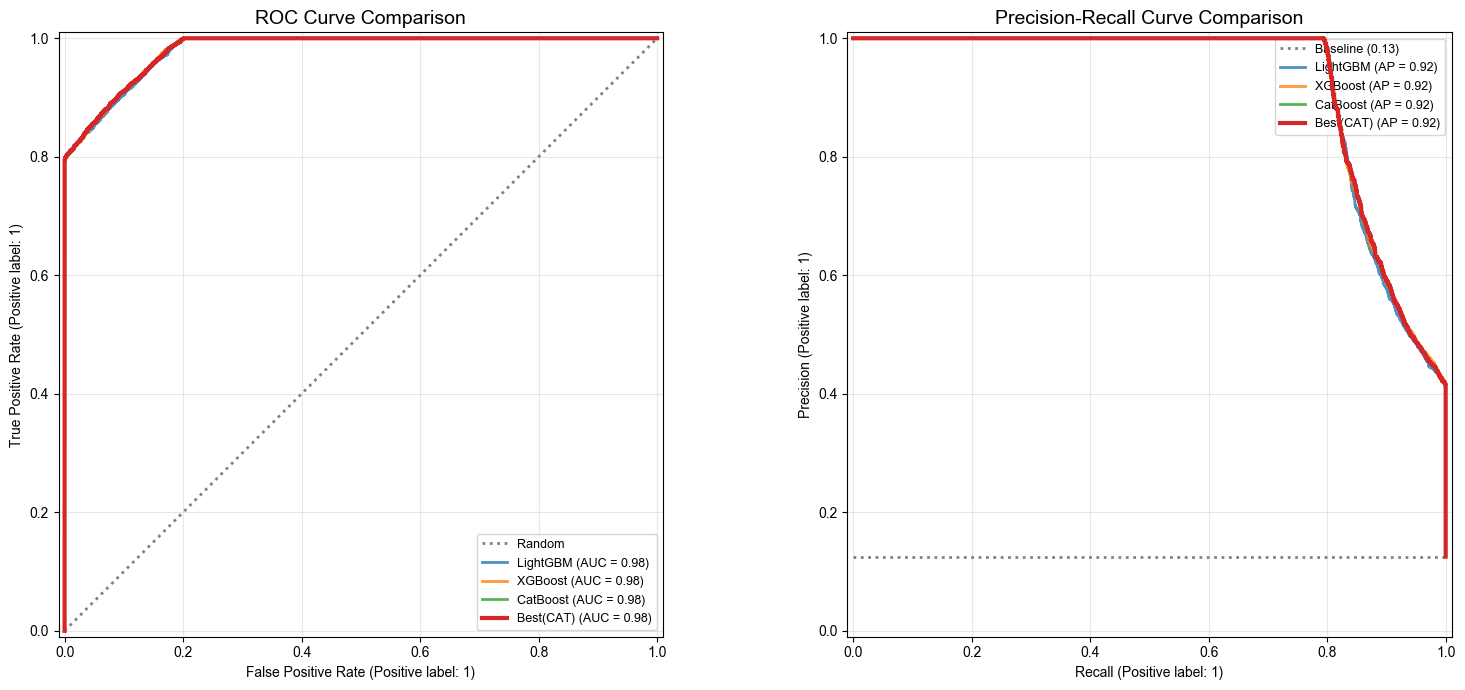

In [28]:
from utils import plot_roc_pr_curve

plot_data = [
    # --- 提升树模型 (Boosting) ---
    (oof_lgb,  'LightGBM', {'lw': 2, 'alpha': 0.8}),
    (oof_xgb,  'XGBoost',  {'lw': 2, 'alpha': 0.8}),
    (oof_cat,  'CatBoost', {'lw': 2, 'alpha': 0.8}),

    # --- 最佳单模型（无融合） ---
    (best_model_oof, f'Best({best_short})', {'lw': 3, 'alpha': 1.0, 'zorder': 10}),
    
    # --- 融合模型 (Ensemble) ---
]
plot_roc_pr_curve(train_y, plot_data)
save_paper_figure('roc_pr_all_models.png')

正在筛选最佳单模型...

>>> 最佳模型: 【CatBoost】
>>> 最佳 F1 : 0.8853
>>> 最佳阈值: 0.7155


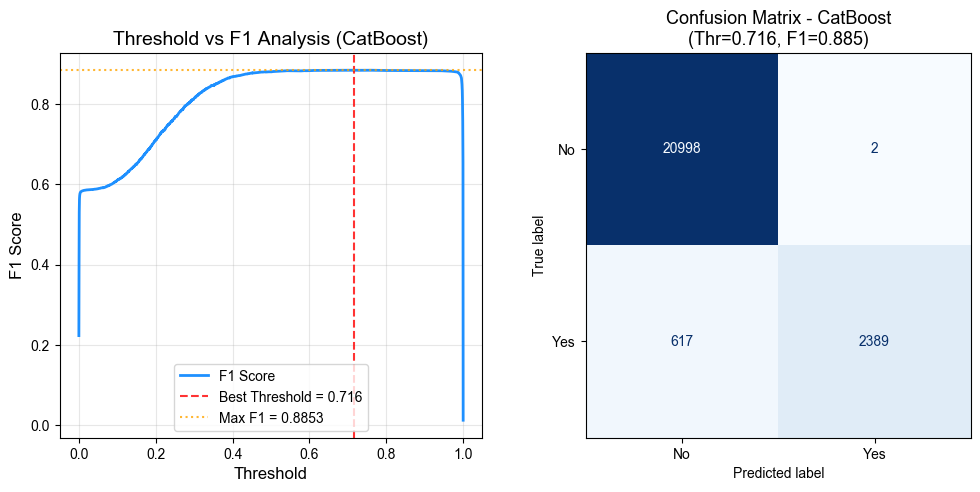

In [29]:
from utils import plot_best_model_analysis

# ======================================================
# 1. 筛选最好单模
# ======================================================
candidates = {
    'LightGBM': oof_lgb,
    'XGBoost': oof_xgb,
    'CatBoost': oof_cat
}

best_model_name = None
best_model_oof = None
global_best_f1 = -1
global_best_thr = -1

print("正在筛选最佳单模型...")
for name, oof_pred in candidates.items():
    # 计算该模型下的最佳阈值和F1
    p, r, t = precision_recall_curve(train_y, oof_pred)
    f1_scores = 2 * (p * r) / (p + r + 1e-8)

    idx = np.argmax(f1_scores)
    current_max_f1 = f1_scores[idx]
    
    current_best_thr = t[idx] if idx < len(t) else t[-1]
    
    if current_max_f1 > global_best_f1:
        global_best_f1 = current_max_f1
        global_best_thr = current_best_thr
        best_model_name = name
        best_model_oof = oof_pred

print(f"\n>>> 最佳模型: 【{best_model_name}】")
print(f">>> 最佳 F1 : {global_best_f1:.4f}")
print(f">>> 最佳阈值: {global_best_thr:.4f}")

# ======================================================
# 绘制最佳单模型的 阈值-F1 曲线 和 混淆矩阵
# ======================================================
plot_best_model_analysis(
    train_y, best_model_name, best_model_oof, global_best_f1, global_best_thr,
    display_labels=label_map_int2str.values(),
)
save_exp_figure(f'threshold_f1_confusion_matrix_{best_model_name.replace(" ", "_")}')
plt.show()
plt.close()

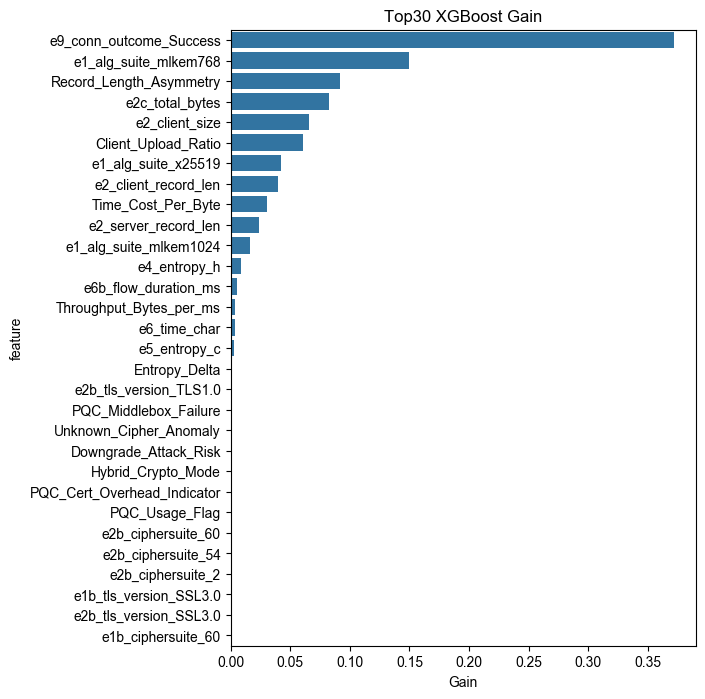

In [30]:
from utils import plot_feature_importance

feature_names = list(X_train.columns)
# ========== 特征重要性（XGBoost示例） ==========
plot_feature_importance(model=m_xgb, feature_names=feature_names)
save_exp_figure('xgb_importance.png')

In [31]:
# ------------------------------------------------------------------
# SHAP 汇总（用融合模型代表）
# ------------------------------------------------------------------
print('>>> SHAP 解释性（融合模型代表）')
explainer = shap.TreeExplainer(m_xgb)          # 可用 m_xgb / m_lgb / m_cat
sample_num = 2000  # 建议保留 sample_num 以防止全量数据导致内存溢出
X_subset = X_train.iloc[:sample_num]
shap_values_raw = explainer.shap_values(X_subset)  # 计算 SHAP 值

if isinstance(shap_values_raw, list):
    shap_values = shap_values_raw[1]
    if isinstance(explainer.expected_value, (list, np.ndarray)):
        expected_value = explainer.expected_value[1]
    else:
        expected_value = explainer.expected_value
else:
    shap_values = shap_values_raw
    expected_value = explainer.expected_value

>>> SHAP 解释性（融合模型代表）


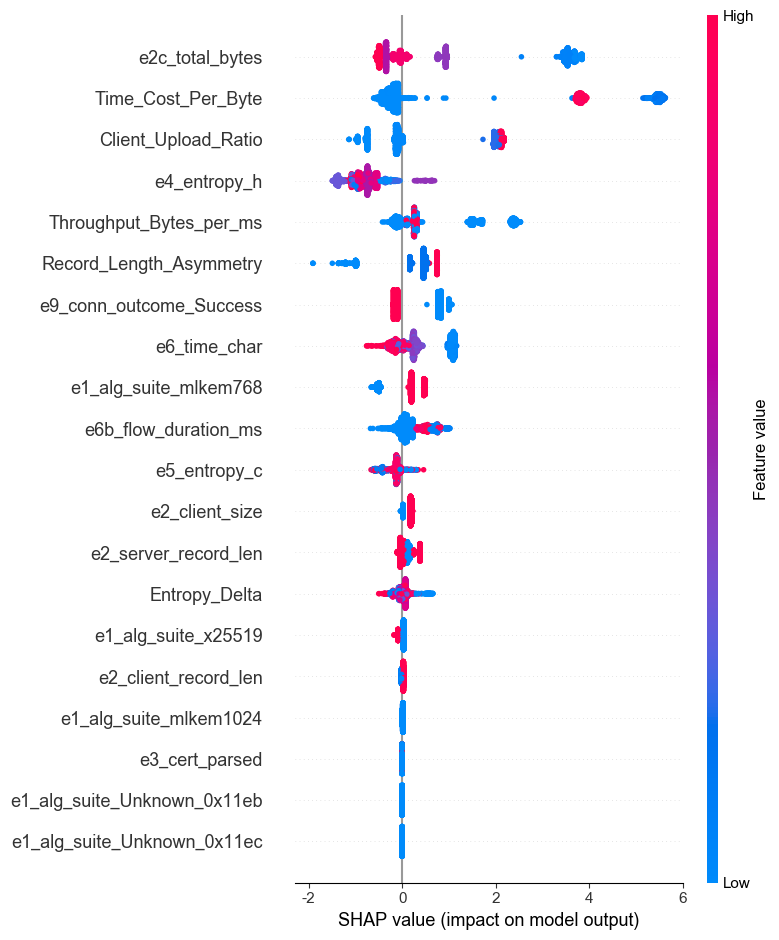

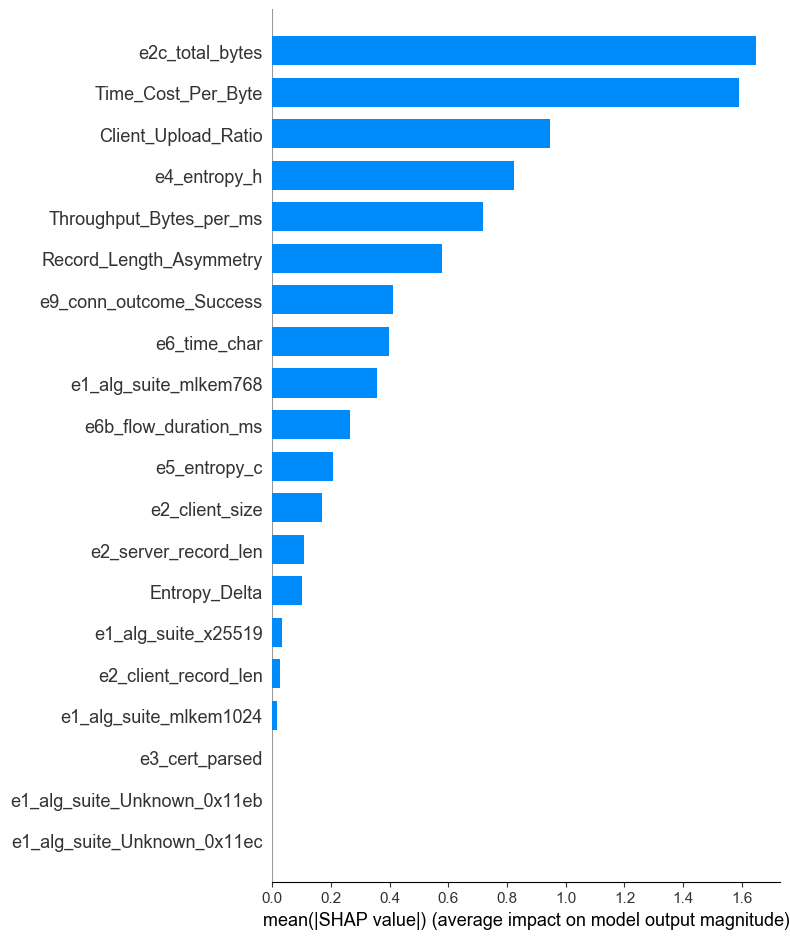

In [32]:
# === 1. 摘要图 (Summary Plot) ===
plt.figure()
shap.summary_plot(shap_values, X_subset, feature_names=feature_names, show=False)
plt.tight_layout()
# save_exp_figure("shap_summary.png", dpi=300)
save_paper_figure("fig4_shap_summary.png", dpi=300)
plt.show()
plt.close()

# === 摘要条形图 (Bar Plot) ===
plt.figure()
shap.summary_plot(shap_values, X_subset, feature_names=feature_names, plot_type="bar", show=False)
plt.tight_layout()
# save_exp_figure("shap_bar.png", dpi=300)
save_paper_figure("fig3_shap_bar.png", dpi=300)
plt.show()
plt.close()

<Figure size 640x480 with 0 Axes>

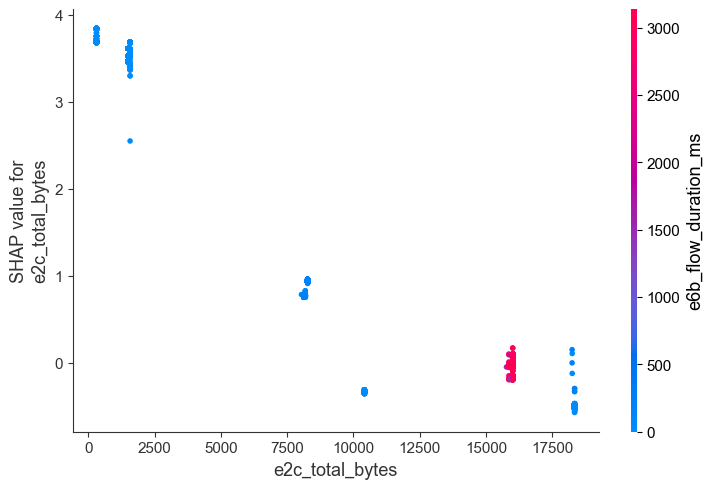

In [33]:
# === 2. SHAP 依赖图（最重要特征） ===
top_feat_idx = np.abs(shap_values).mean(0).argmax() 
plt.figure()
shap.dependence_plot(top_feat_idx, shap_values, X_subset, feature_names=feature_names, show=False)
plt.tight_layout()
# save_exp_figure("shap_dependence.png", dpi=300)
save_paper_figure("fig5_shap_dependence.png", dpi=300)
plt.show()
plt.close()

<Figure size 640x480 with 0 Axes>

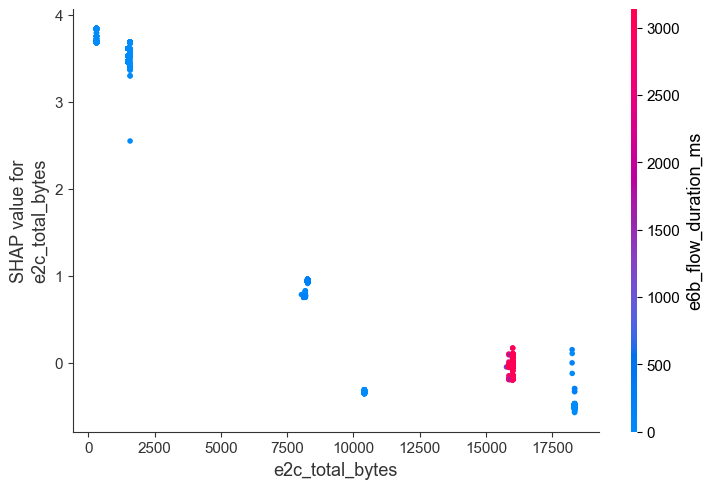

<Figure size 640x480 with 0 Axes>

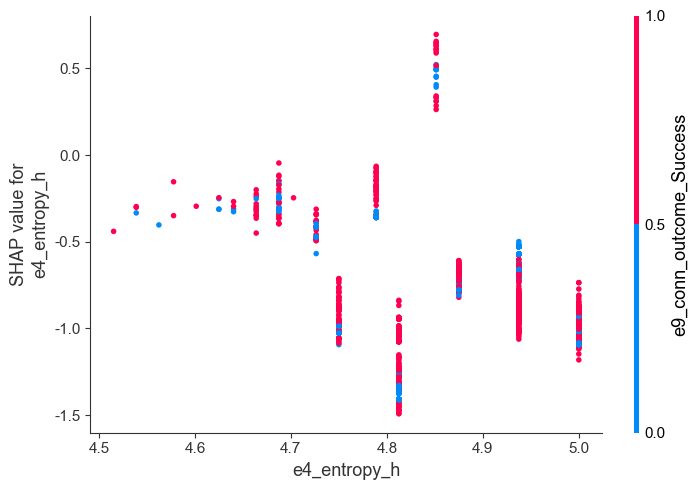

<Figure size 640x480 with 0 Axes>

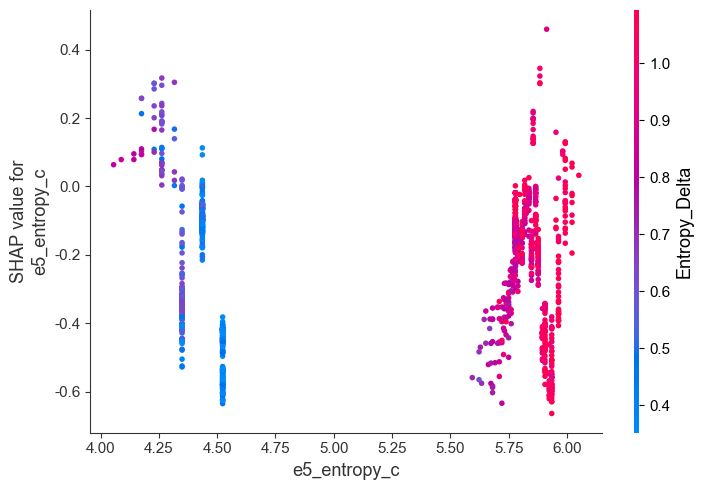

In [34]:
# === 2b. SHAP 依赖图（指定特征：Interest Rate / Annual Income） ===
specified_features = ['e2c_total_bytes', 'e4_entropy_h', 'e5_entropy_c']
specifieidxd_idx = [i for i, _ in enumerate(feature_names) if _ in specified_features]
for fidx, fname in zip(specifieidxd_idx, specified_features):
    plt.figure()
    shap.dependence_plot(
        fidx, shap_values, X_subset,
        feature_names=feature_names, show=False
    )
    plt.tight_layout()
    save_exp_figure(f"shap_dependence_{fname}.png", dpi=300, bbox_inches='tight')
    save_paper_figure(f"shap_dependence_{fname}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

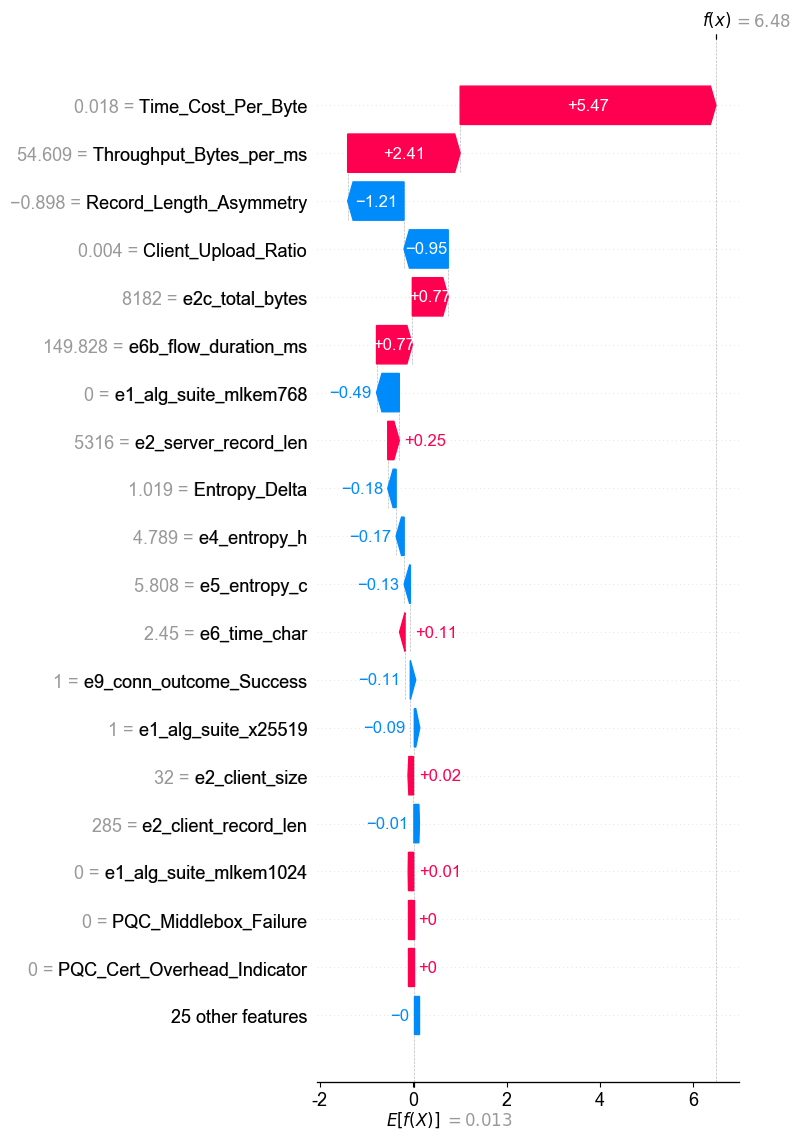

In [35]:
# === 3. SHAP 瀑布图（单样本示例） ===
sample_idx = 0 
plt.figure()
# 使用 Explanation 对象适配新版绘图接口
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[sample_idx],
        base_values=expected_value,
        data=X_subset.iloc[sample_idx],
        feature_names=feature_names
    ),
    max_display=20, show=False
)
plt.tight_layout()
save_exp_figure("shap_waterfall.png", dpi=300)
plt.show()
plt.close()